# Week 10 — data visualization
**Name: Craig**
**Date: November 2nd 2026**
-

In [1]:
# first we need to import our visualization libraries and any other related components!

import json  # needed to parse geojson
import re    # needed for wordcloud example

import matplotlib.pyplot as plt   # for word clouds
import pandas as pd  # using data frames with our plotly visualizations
import plotly.express as px  # px shorthand is used in plotly examples
import pydeck as pdk  # pdk is used as shorthand for pydeck examples

from IPython.display import HTML, IFrame  # needed to display pydeck visualizations in the notebook
from wordcloud import STOPWORDS, WordCloud  # STOPWORDS is a filter for word frequency counting

## Visualizing Poll Data

I've included two files (`house_average_recent.csv` and `senate_average_recent.csv`) which contain average polls for senate and house races for the 2026 US Election. First we want to load these as a dataframe:

In [15]:
house = pd.read_csv("house_average_recent.csv")
senate = pd.read_csv("senate_average_recent.csv")

# preview what's in each file:
house.tail()

,id,state,district,dem,rep,margin,polls,latest,days_old
109,WA-3,WA,3,45.0,44.0,1.0,1,2026-10-21,10
110,WA-5,WA,5,46.5,53.5,-7.0,1,2026-05-25,159
111,WI-1,WI,1,48.5,47.5,1.0,1,2026-10-01,30
112,WI-3,WI,3,50.0,46.0,4.0,2,2026-06-25,128
113,WI-6,WI,6,39.0,61.0,-22.0,1,2026-05-28,156


In [16]:
senate.tail()

,state,dem,rep,margin,polls,latest,days_old
24,SC,44.7,44.3,0.4,5,2026-10-29,3
25,SD,18.0,43.0,-25.0,1,2026-05-30,155
26,TN,32.0,54.5,-22.5,1,2026-08-26,67
27,TX,50.2,45.2,5.0,11,2026-11-01,0
28,VA,45.0,38.0,7.0,1,2025-01-15,655


In [7]:
len(senate)

29

Since our data doesn't cleanly add up to 100% for each senate/house poll average, we need to calculate a 3rd value for "other" to make up the missing points!

other = 100 - dem - rep


In [17]:
# round(1) means round the number to a single decimal point
senate["other"] = (100 - senate["dem"] - senate["rep"]).clip(lower=0).round(1) 

senate.tail()

,state,dem,rep,margin,polls,latest,days_old,other
24,SC,44.7,44.3,0.4,5,2026-10-29,3,11.0
25,SD,18.0,43.0,-25.0,1,2026-05-30,155,39.0
26,TN,32.0,54.5,-22.5,1,2026-08-26,67,13.5
27,TX,50.2,45.2,5.0,11,2026-11-01,0,4.6
28,VA,45.0,38.0,7.0,1,2025-01-15,655,17.0


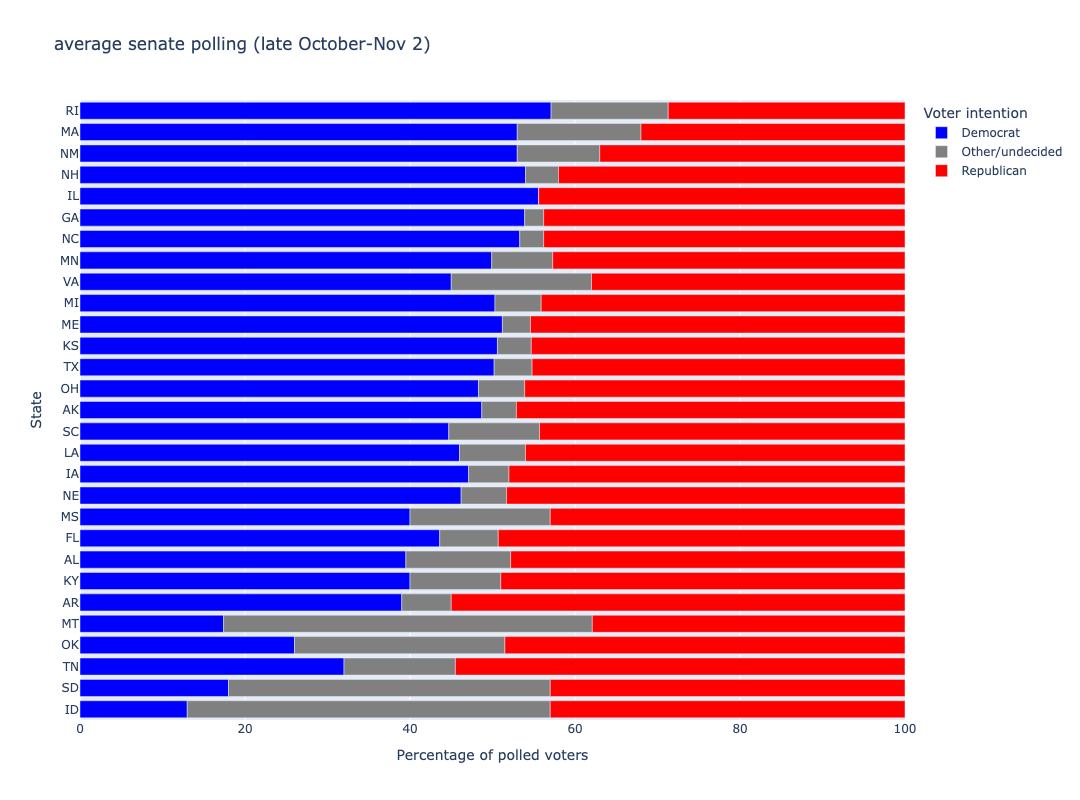

In [14]:
party_names = {"dem": "Democrat",  "other": "Other/undecided", "rep": "Republican"}

colors = {"Democrat": "blue", "Other/undecided": "grey", "Republican": "red"}

senate_sorted = senate.sort_values("margin").rename(columns=party_names)

fig = px.bar(
    senate_sorted, # the data we want to visualize
    x=["Democrat", "Other/undecided", "Republican"], #the x axis
    y="state",  # the y axis
    orientation="h", 
    color_discrete_map=colors, #directly map colors to columns
    labels={"value":"Percent", "state": "State"},
    hover_data={"polls":True,"latest":True}, # selecting extra columns to display on mouse hover
    height=800, # height of graph, setting this explicitly so it's big enough to display everything
    title="average senate polling (late October-Nov 2)"
)

fig.update_layout(
    legend_title_text="Voter intention",
    xaxis_title="Percentage of polled voters",
    xaxis_range=[0,100]  # stretches data across full width of graph
)

fig.show()  # displays the graph

## Plotting the data on a map!

We can generate a geographic map using our data, combining it with region shapes (states, congressional districts, etc)

Plotly contains US state outlines by default so we don't need to add them

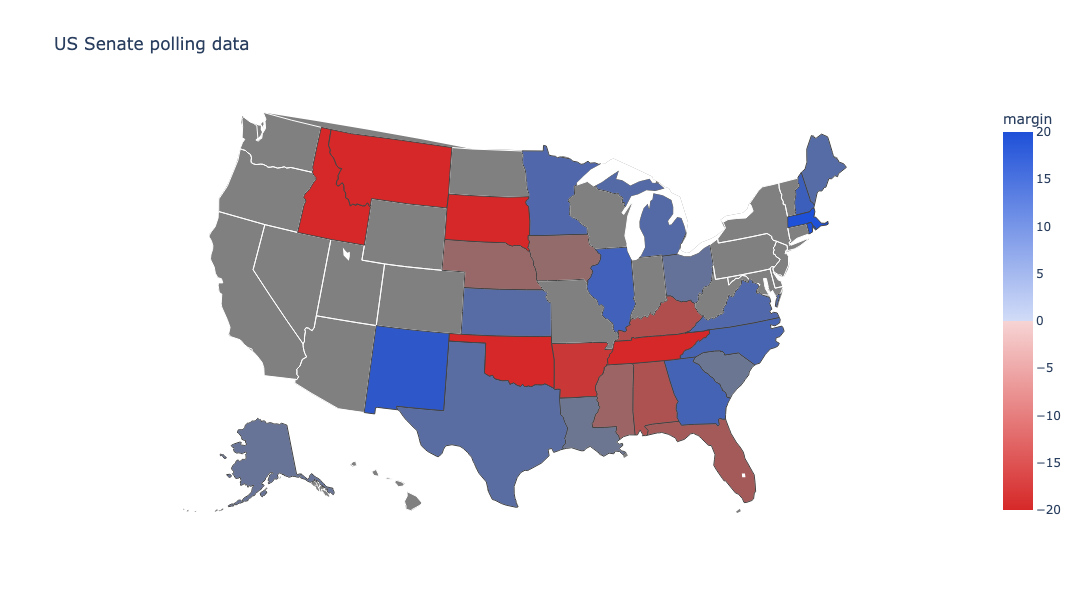

In [22]:
red = "214, 40, 40"  # is the RGB representation of "red"
blue = "30, 80, 216"  # rgb representation of blue

# we can define a color scale by which our data will be represented

color_scale = [
    [0.0, f"rgba({red}, 1)"], # 1 is most opaque for the "a" value of rgba color
    [0.5, f"rgba({red}, 0.2)"], # 0.2 will read as barely opaque
    [0.5, f"rgba({blue}, 0.2)"],
    [1.0, f"rgba({blue}, 1)"]
]

colorbar = {
    "title": "Lead by margin",
    "tickvals": [-20, -10, 0, 10, 20],
    "ticktext": ["R+20", "R+10", "Tie", "D+10", "D+20"],
}

fig = px.choropleth(
    senate,
    locations="state", # this tells the plotly library which column of our data contains location information
    locationmode="USA-states", # this tells plotly that we are dealing with US state data and to plot accordlingly
    scope="usa", # zooms in on the US,
    color="margin", #give color to each region based on "margin" column of dataset
    color_continuous_scale=color_scale,
    range_color=[-20,20],
    height=600,
    title="US Senate polling data"
)

fig.update_geos(landcolor="grey")

fig.show()